In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from skimpy import skim
from scipy import stats

# Configuração visual padrão
plt.rcParams["figure.figsize"] = (12, 5)
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# 1. Carregamento de todas as abas via OpenPyXL
CAMINHO_ARQUIVO = "Path(__file__).resolve().parents[1] / "data" / "Base_Dados_OrbitShop.xlsx""
abas = pd.read_excel(CAMINHO_ARQUIVO, sheet_name=None, engine="openpyxl")

print("Abas encontradas:", list(abas.keys()))
for nome, df in abas.items():
    print(f" - {nome}: {df.shape[0]:,} linhas x {df.shape[1]} colunas | Colunas: {list(df.columns)}")

Abas encontradas: ['Leia-me', 'Clientes', 'Produtos', 'Pedidos', 'Itens_Pedido', 'Tickets_Suporte', 'Avaliacoes']
 - Leia-me: 25 linhas x 2 colunas | Colunas: ['Unnamed: 0', 'Unnamed: 1']
 - Clientes: 3,000 linhas x 8 colunas | Colunas: ['id', 'nome', 'email', 'cidade', 'estado', 'data_cadastro', 'segmento', 'canal_aquisicao']
 - Produtos: 200 linhas x 7 colunas | Colunas: ['id', 'nome', 'categoria', 'subcategoria', 'preco_unitario', 'custo_unitario', 'fornecedor']
 - Pedidos: 15,000 linhas x 7 colunas | Colunas: ['id', 'cliente_id', 'data_pedido', 'status', 'valor_total', 'canal_venda', 'cupom_desconto']
 - Itens_Pedido: 36,740 linhas x 6 colunas | Colunas: ['id', 'pedido_id', 'produto_id', 'quantidade', 'preco_praticado', 'desconto_aplicado']
 - Tickets_Suporte: 4,000 linhas x 7 colunas | Colunas: ['id', 'pedido_id', 'cliente_id', 'categoria_problema', 'data_abertura', 'data_resolucao', 'status']
 - Avaliacoes: 8,000 linhas x 7 colunas | Colunas: ['id', 'pedido_id', 'produto_id', 'cl


TABELA: LEIA-ME
Linhas duplicadas exatas: 9

Colunas com valores nulos:
  * Unnamed: 0: 25 (100.00%)
  * Unnamed: 1: 10 (40.00%)


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 25     │ │ float64     │ 1     │                                                          │
│ │ Number of columns │ 2      │ │ string      │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                    All null                                                     │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column                                                   ┃ NA                 ┃ NA %                       ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │ Unnamed: 0                                               │                 25 │                        100 │  │
│ └──────────────────────────────────────────────────────────┴────────────────────┴────────────────────────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┓  │
│ ┃           ┃    ┃      ┃           ┃           ┃           ┃           ┃ chars per ┃ words per  ┃ total     ┃  │
│ ┃ column    ┃ NA ┃ NA % ┃ shortest  ┃ longest   ┃ min       ┃ max       ┃ row       ┃ row        ┃ words     ┃  │
│ ┡━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━┩  │
│ │ Unnamed:  │ 10 │   40 │ Sobre     │ Esta base │ Aviso     │ •         │       114 │         11 │       276 │  │
│ │ 1         │    │      │ esta base │ NÃO foi   │ important │ Tickets_S │           │            │           │  │
│ │           │    │      │           │ previamen │ e         │ uporte —  │           │            │           │  │
│ │           │    │      │           │ te limpa. │           │ 4.000     │           │            │           │  │
│ │           │    │      │           │ Ela       │           │ registros │           │            │           │  │
│ │           │    │      │           │ contém    │           │ .         │           │            │           │  │
│ │           │    │      │           │ campos    │           │ pedido_id │           │            │           │  │
│ │           │    │      │           │ vazios    │           │ →         │           │            │           │  │
│ │           │    │      │           │ (por      │           │ Pedidos.i │           │            │           │  │
│ │           │    │      │           │ exemplo,  │           │ d ·       │           │            │           │  │
│ │           │    │      │           │ em        │           │ cliente_i │           │            │           │  │
│ │           │    │      │           │ valor_tot │           │ d →       │           │            │           │  │
│ │           │    │      │           │ al de     │           │ Clientes. │           │            │           │  │
│ │           │    │      │           │ Pedidos e │           │ id.       │           │            │           │  │
│ │           │    │      │           │ em        │           │           │           │            │           │  │
│ │           │    │      │           │ desconto_ │     


TABELA: CLIENTES
Linhas duplicadas exatas: 0
IDs duplicados ('id'): 0 | IDs nulos: 0

Nenhum valor nulo encontrado.


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 3000   │ │ string      │ 7     │                                                          │
│ │ Number of columns │ 8      │ │ int64       │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓  │
│ ┃ column     ┃ NA   ┃ NA %    ┃ mean    ┃ sd       ┃ p0   ┃ p25      ┃ p50     ┃ p75     ┃ p100   ┃ hist     ┃  │
│ ┡━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩  │
│ │ id         │    0 │       0 │    1500 │    866.2 │    1 │    750.8 │    1500 │    2250 │   3000 │  ██████  │  │
│ └────────────┴──────┴─────────┴─────────┴──────────┴──────┴──────────┴─────────┴─────────┴────────┴──────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃           ┃    ┃      ┃           ┃           ┃           ┃           ┃ chars per ┃ words per ┃ total      ┃  │
│ ┃ column    ┃ NA ┃ NA % ┃ shortest  ┃ longest   ┃ min       ┃ max       ┃ row       ┃ row       ┃ words      ┃  │
│ ┡━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩  │
│ │ nome      │  0 │    0 │ Ana Dias  │ Guilherme │ Amanda    │ Zélia     │      13.6 │         2 │       6000 │  │
│ │           │    │      │           │ Cavalcant │ Almeida   │ Vieira    │           │           │            │  │
│ │           │    │      │           │ i         │           │           │           │           │            │  │
│ │ email     │  0 │    0 │ ana.dias8 │ guilherme │ amanda.al │ zelia.vie │      28.3 │         1 │       3000 │  │
│ │           │    │      │ 81@gmail. │ .cavalcan │ meida379@ │ ira96@out │           │           │            │  │
│ │           │    │      │ com       │ ti967@ter │ outlook.c │ look.com  │           │           │            │  │
│ │           │    │      │           │ ra.com.br │ om        │           │           │           │            │  │
│ │ cidade    │  0 │    0 │ Serra     │ Aparecida │ Ananindeu │ Teresina  │      9.16 │       1.5 │       4395 │  │
│ │           │    │      │           │ de        │ a         │           │           │           │            │  │
│ │           │    │      │           │ Goiânia   │           │           │           │           │            │  │
│ │ estado    │  0 │    0 │ PI        │ PI        │ AL        │ SP        │         2 │         1 │       3000 │  │
│ │ data_cada │  0 │    0 │ 2023-02-2 │ 2023-02-2 │ 2022-11-0 │ 2024-12-2 │        10 │         1 │       3000 │  │
│ │ stro      │    │      │ 0         │ 0         │ 6         │ 8         │           │           │            │  │
│ │ segmento  │  0 │    0 │ B2C       │ B2C       │ B2B       │ B2C       │         3 │         1 │       3000 │  │
│ │ canal_aqu │  0 │    0 │ orgânico  │ redes_soc │ indicação │ redes_soc │      10.3 │         1 │       3000 │  │
│ │ isicao    │    │      │           │ iais      │     


TABELA: PRODUTOS
Linhas duplicadas exatas: 0
IDs duplicados ('id'): 0 | IDs nulos: 0

Nenhum valor nulo encontrado.


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 200    │ │ string      │ 4     │                                                          │
│ │ Number of columns │ 7      │ │ float64     │ 2     │                                                          │
│ └───────────────────┴────────┘ │ int64       │ 1     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column             ┃ NA  ┃ NA %   ┃ mean    ┃ sd     ┃ p0     ┃ p25    ┃ p50    ┃ p75    ┃ p100  ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━━┩  │
│ │ id                 │   0 │      0 │   100.5 │  57.88 │      1 │  50.75 │  100.5 │  150.2 │   200 │ ██████  │  │
│ │ preco_unitario     │   0 │      0 │    1719 │   1003 │  36.28 │  876.9 │   1685 │   2635 │  3496 │ ▇█▆▇▅▆  │  │
│ │ custo_unitario     │   0 │      0 │   976.3 │  588.5 │  16.67 │    462 │  992.3 │   1389 │  2319 │ ▇▆█▆▃▂  │  │
│ └────────────────────┴─────┴────────┴─────────┴────────┴────────┴────────┴────────┴────────┴───────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃           ┃    ┃      ┃           ┃           ┃           ┃           ┃ chars per ┃ words per ┃ total      ┃  │
│ ┃ column    ┃ NA ┃ NA % ┃ shortest  ┃ longest   ┃ min       ┃ max       ┃ row       ┃ row       ┃ words      ┃  │
│ ┡━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩  │
│ │ nome      │  0 │    0 │ Vasos 67  │ Equipamen │ Acessório │ Vitaminas │      13.6 │       2.4 │        478 │  │
│ │           │    │      │           │ tos de    │ s 163     │ 198       │           │           │            │  │
│ │           │    │      │           │ Academia  │           │           │           │           │            │  │
│ │           │    │      │           │ 170       │           │           │           │           │            │  │
│ │ categoria │  0 │    0 │ Moda      │ Alimentos │ Alimentos │ Moda      │      13.6 │       2.4 │        476 │  │
│ │           │    │      │           │ & Bebidas │ & Bebidas │           │           │           │            │  │
│ │ subcatego │  0 │    0 │ Chás      │ Equipamen │ Acessório │ Vitaminas │      10.2 │       1.4 │        278 │  │
│ │ ria       │    │      │           │ tos de    │ s         │           │           │           │            │  │
│ │           │    │      │           │ Academia  │           │           │           │           │            │  │
│ │ fornecedo │  0 │    0 │ AlphaSupp │ MarcoPolo │ AlphaSupp │ TechBrasi │      15.3 │       1.7 │        334 │  │
│ │ r         │    │      │ ly        │ Distribui │ ly        │ l Ltda    │           │           │            │  │
│ │           │    │      │           │ ção       │           │           │           │           │            │  │
│ └───────────┴────┴──────┴───────────┴───────────┴─────

... (4 outputs left out)


TABELA: TICKETS_SUPORTE
Linhas duplicadas exatas: 0
IDs duplicados ('id'): 0 | IDs nulos: 0

Colunas com valores nulos:
  * data_resolucao: 1,653 (41.33%)


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 4000   │ │ string      │ 4     │                                                          │
│ │ Number of columns │ 7      │ │ int64       │ 3     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column         ┃ NA   ┃ NA %   ┃ mean   ┃ sd       ┃ p0   ┃ p25     ┃ p50    ┃ p75     ┃ p100    ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━┩  │
│ │ id             │    0 │      0 │   2000 │     1155 │    1 │    1001 │   2000 │    3000 │    4000 │ ██████  │  │
│ │ pedido_id      │    0 │      0 │   7577 │     4320 │    6 │    3880 │   7648 │   11300 │   15000 │ ██▇███  │  │
│ │ cliente_id     │    0 │      0 │   1503 │    863.2 │    1 │   759.8 │   1501 │    2256 │    3000 │ ████▇█  │  │
│ └────────────────┴──────┴────────┴────────┴──────────┴──────┴─────────┴────────┴─────────┴─────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┓  │
│ ┃           ┃      ┃        ┃           ┃          ┃           ┃          ┃ chars per ┃ words    ┃ total     ┃  │
│ ┃ column    ┃ NA   ┃ NA %   ┃ shortest  ┃ longest  ┃ min       ┃ max      ┃ row       ┃ per row  ┃ words     ┃  │
│ ┡━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━┩  │
│ │ categoria │    0 │      0 │ troca     │ cobrança │ atraso    │ troca    │      6.31 │        1 │      4000 │  │
│ │ _problema │      │        │           │          │           │          │           │          │           │  │
│ │ data_aber │    0 │      0 │ 2023-05-2 │ 2023-05- │ 2023-01-0 │ 2024-12- │        10 │        1 │      4000 │  │
│ │ tura      │      │        │ 1         │ 21       │ 4         │ 31       │           │          │           │  │
│ │ data_reso │ 1653 │ 41.325 │ 2024-05-0 │ 2024-05- │ 2023-01-1 │ 2025-01- │        10 │     0.59 │      2347 │  │
│ │ lucao     │      │        │ 9         │ 09       │ 0         │ 20       │           │          │           │  │
│ │ status    │    0 │      0 │ aberto    │ resolvid │ aberto    │ resolvid │      8.18 │        1 │      4000 │  │
│ │           │      │        │           │ o        │           │ o        │           │          │           │  │
│ └───────────┴──────┴────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯


TABELA: AVALIACOES
Linhas duplicadas exatas: 0
IDs duplicados ('id'): 0 | IDs nulos: 0

Colunas com valores nulos:
  * comentario: 1,679 (20.99%)


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 8000   │ │ int64       │ 5     │                                                          │
│ │ Number of columns │ 7      │ │ string      │ 2     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column         ┃ NA   ┃ NA %   ┃ mean    ┃ sd      ┃ p0   ┃ p25     ┃ p50    ┃ p75     ┃ p100    ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━┩  │
│ │ id             │    0 │      0 │    4000 │    2310 │    1 │    2001 │   4000 │    6000 │    8000 │ ██████  │  │
│ │ pedido_id      │    0 │      0 │    7494 │    4319 │    2 │    3770 │   7469 │   11220 │   15000 │ ██████  │  │
│ │ produto_id     │    0 │      0 │   100.3 │   57.45 │    1 │      51 │    100 │     149 │     200 │ ██████  │  │
│ │ cliente_id     │    0 │      0 │    1504 │   861.8 │    1 │   766.8 │   1510 │    2254 │    3000 │ ██████  │  │
│ │ nota           │    0 │      0 │   3.583 │   1.366 │    1 │       3 │      4 │       5 │       5 │ ▃▃ ▄▆█  │  │
│ └────────────────┴──────┴────────┴─────────┴─────────┴──────┴─────────┴────────┴─────────┴─────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┓  │
│ ┃           ┃      ┃         ┃          ┃           ┃          ┃           ┃ chars    ┃ words per ┃ total    ┃  │
│ ┃ column    ┃ NA   ┃ NA %    ┃ shortest ┃ longest   ┃ min      ┃ max       ┃ per row  ┃ row       ┃ words    ┃  │
│ ┡━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━┩  │
│ │ comentari │ 1679 │ 20.9875 │ Produto  │ Entrega   │ Demorou  │ Veio      │     32.3 │       3.6 │    28537 │  │
│ │ o         │      │         │ veio com │ rápida e  │ muito    │ diferente │          │           │          │  │
│ │           │      │         │ defeito. │ produto   │ para     │ do        │          │           │          │  │
│ │           │      │         │          │ conforme  │ chegar.  │ anunciado │          │           │          │  │
│ │           │      │         │          │ descrito. │          │ .         │          │           │          │  │
│ │ data_aval │    0 │       0 │ 2024-11- │ 2024-11-0 │ 2023-01- │ 2024-12-3 │       10 │         1 │     8000 │  │
│ │ iacao     │      │         │ 07       │ 7         │ 05       │ 1         │          │           │          │  │
│ └───────────┴──────┴─────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

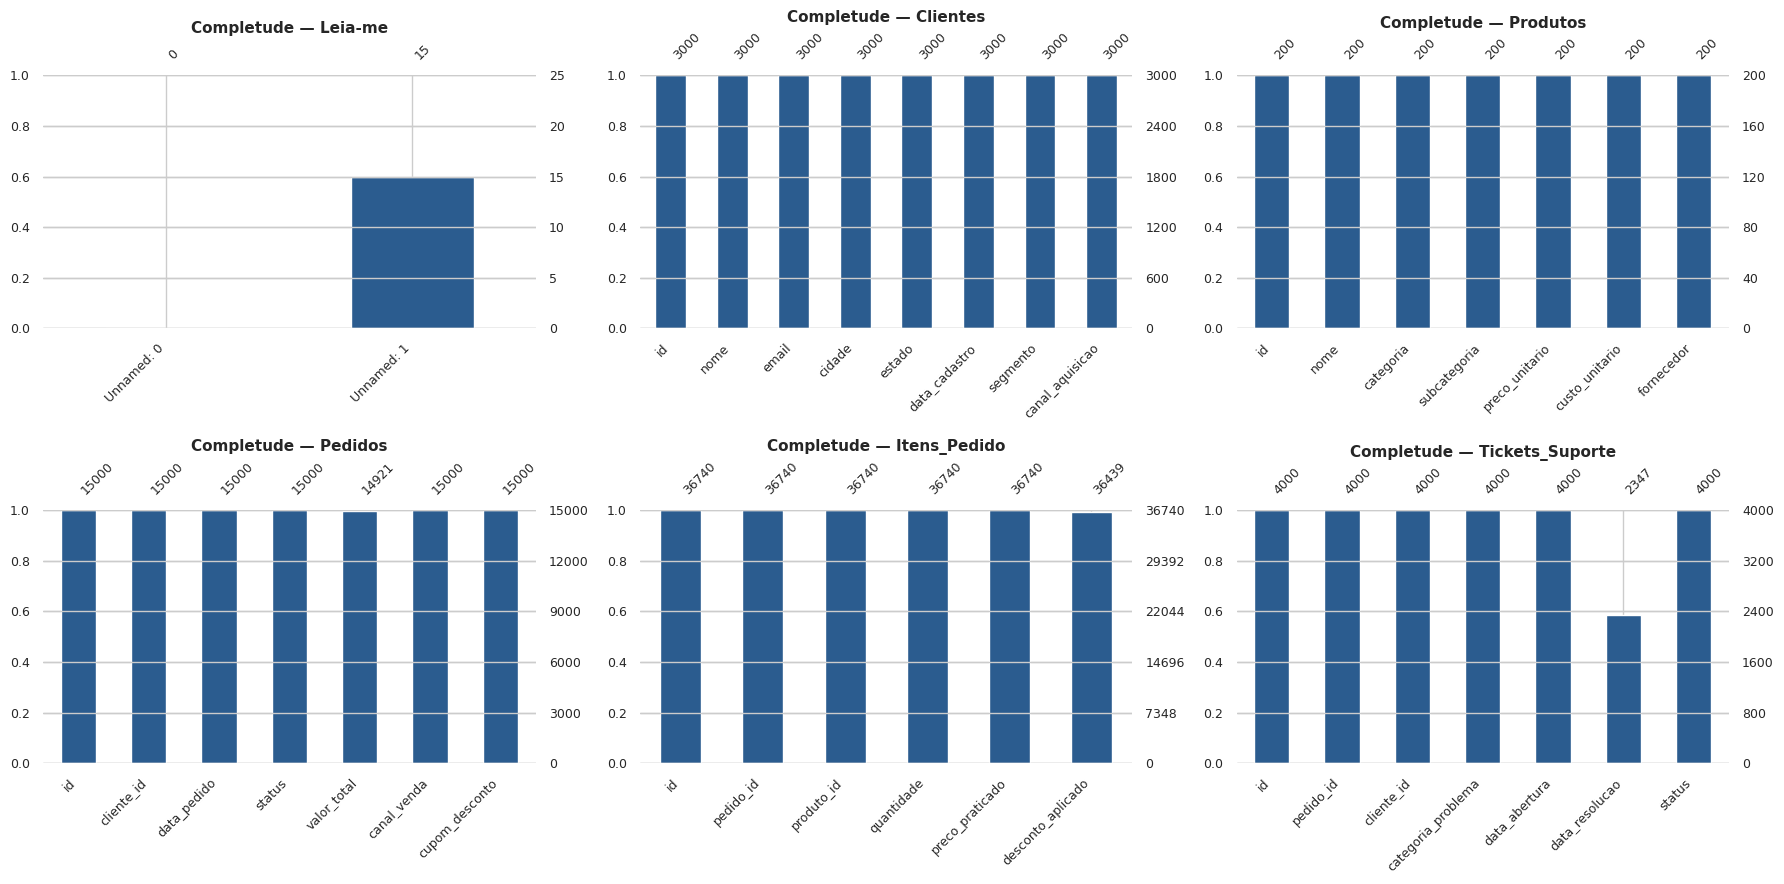

In [13]:
# 2. Auditoria de Qualidade, Nulos e Chaves
for nome, df in abas.items():
    print(f"\n{'='*80}\nTABELA: {nome.upper()}\n{'='*80}")
    print(f"Linhas duplicadas exatas: {df.duplicated().sum()}")
    if "id" in df.columns:
        print(f"IDs duplicados ('id'): {df['id'].duplicated().sum()} | IDs nulos: {df['id'].isna().sum()}")

    # Resumo de nulos
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0]
    if not nulos.empty:
        print("\nColunas com valores nulos:")
        for col, qtd in nulos.items():
            print(f"  * {col}: {qtd:,} ({qtd/len(df)*100:.2f}%)")
    else:
        print("\nNenhum valor nulo encontrado.")

    skim(df)

# Visualização consolidada de nulos nas principais tabelas
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (nome, df) in zip(axes.flat, abas.items()):
    msno.bar(df, ax=ax, fontsize=9, color="#2b5c8f")
    ax.set_title(f"Completude — {nome}", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
# Separando apenas as 6 tabelas transacionais e tipando datas
clientes = abas["Clientes"].copy()
produtos = abas["Produtos"].copy()
pedidos = abas["Pedidos"].copy()
itens = abas["Itens_Pedido"].copy()
tickets = abas["Tickets_Suporte"].copy()
avaliacoes = abas["Avaliacoes"].copy()

for df, cols in [
    (clientes, ["data_cadastro"]),
    (pedidos, ["data_pedido"]),
    (tickets, ["data_abertura", "data_resolucao"]),
    (avaliacoes, ["data_avaliacao"]),
]:
    for c in cols:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# 1. Integridade Referencial (Chaves Órfãs) e Consistência Temporal
print("=== 1. AUDITORIA DE INTEGRIDADE RELACIONAL E TEMPORAL ===")
print("Pedidos sem cliente válido:", (~pedidos["cliente_id"].isin(clientes["id"])).sum())
print("Itens sem pedido válido:", (~itens["pedido_id"].isin(pedidos["id"])).sum())
print("Itens sem produto válido:", (~itens["produto_id"].isin(produtos["id"])).sum())
print("Pedidos sem nenhum item:", (~pedidos["id"].isin(itens["pedido_id"])).sum())
print("Tickets sem pedido válido:", (~tickets["pedido_id"].isin(pedidos["id"])).sum())
print("Avaliações sem pedido válido:", (~avaliacoes["pedido_id"].isin(pedidos["id"])).sum())

# Checagem de datas impossíveis
ped_cli = pedidos.merge(clientes[["id", "data_cadastro"]], left_on="cliente_id", right_on="id", suffixes=("", "_cli"))
print("Pedidos com data anterior ao cadastro do cliente:", (ped_cli["data_pedido"] < ped_cli["data_cadastro"]).sum())
print("Tickets com resolução anterior à abertura:", (tickets["data_resolucao"] < tickets["data_abertura"]).sum())
print("Tickets 'resolvido' sem data_resolucao:", ((tickets["status"] == "resolvido") & (tickets["data_resolucao"].isna())).sum())
print("Tickets 'aberto' com data_resolucao preenchida:", ((tickets["status"] != "resolvido") & (tickets["data_resolucao"].notna())).sum())

# 2. Reconciliação Financeira (Q6)
itens_full = itens.merge(
    produtos[["id", "nome", "categoria", "preco_unitario", "custo_unitario", "fornecedor"]],
    left_on="produto_id", right_on="id", suffixes=("", "_prod")
)

# Cálculo de receita por item (assumindo desconto nulo = 0)
itens_full["desc_efetivo"] = itens_full["desconto_aplicado"].fillna(0)
itens_full["subtotal_bruto"] = itens_full["quantidade"] * itens_full["preco_praticado"]
itens_full["subtotal_liquido"] = itens_full["subtotal_bruto"] * (1 - itens_full["desc_efetivo"])
itens_full["custo_total_item"] = itens_full["quantidade"] * itens_full["custo_unitario"]
itens_full["lucro_item"] = itens_full["subtotal_liquido"] - itens_full["custo_total_item"]

print("\n=== 2. AUDITORIA DE PREÇOS E MARGEM NOS ITENS ===")
diff_preco_catalogo = ~np.isclose(itens_full["preco_praticado"], itens_full["preco_unitario"], atol=0.01)
print(f"Itens com preco_praticado diferente do catálogo: {diff_preco_catalogo.sum():,} ({diff_preco_catalogo.mean()*100:.2f}%)")
print(f"Itens vendidos abaixo do custo (margem < 0): {(itens_full['lucro_item'] < 0).sum():,}")
print(f"Desconto aplicado > 0 quando cupom_desconto == 'não': ", end="")
itens_cupom = itens_full.merge(pedidos[["id", "cupom_desconto"]], left_on="pedido_id", right_on="id")
print(((itens_cupom["cupom_desconto"] == "não") & (itens_cupom["desc_efetivo"] > 0)).sum())
print(f"Desconto aplicado == 0 quando cupom_desconto == 'sim': ", end="")
print(((itens_cupom["cupom_desconto"] == "sim") & (itens_cupom["desc_efetivo"] == 0)).sum())

# Agregação por pedido para comparar com Pedidos.valor_total
agg_itens = itens_full.groupby("pedido_id", as_index=False).agg(
    qtd_itens=("id", "count"),
    unidades=("quantidade", "sum"),
    soma_bruta_itens=("subtotal_bruto", "sum"),
    soma_liquida_itens=("subtotal_liquido", "sum"),
    custo_pedido=("custo_total_item", "sum"),
    lucro_pedido=("lucro_item", "sum"),
    tem_desc_nulo=("desconto_aplicado", lambda s: s.isna().any())
)

rec = pedidos.merge(agg_itens, left_on="id", right_on="pedido_id", how="left")
rec["diff_liquida"] = rec["valor_total"] - rec["soma_liquida_itens"]
rec["diff_bruta"] = rec["valor_total"] - rec["soma_bruta_itens"]

validos = rec[rec["valor_total"].notna()].copy()
bate_liq = np.isclose(validos["diff_liquida"], 0, atol=0.05)
bate_bru = np.isclose(validos["diff_bruta"], 0, atol=0.05)

print("\n=== 3. RECONCILIAÇÃO PEDIDOS vs. ITENS_PEDIDO (Q6) ===")
print(f"Total de pedidos: {len(rec):,} | Com valor_total nulo: {rec['valor_total'].isna().sum()}")
print(f"Pedidos (com valor_total) que batem com soma líquida dos itens (±R$0,05): {bate_liq.sum():,} ({bate_liq.mean()*100:.2f}%)")
print(f"Pedidos (com valor_total) que batem com soma bruta dos itens (±R$0,05): {bate_bru.sum():,} ({bate_bru.mean()*100:.2f}%)")
print(f"Pedidos divergentes da soma líquida: {(~bate_liq).sum():,}")
print(f"\nSoma total de valor_total (Pedidos): R$ {rec['valor_total'].sum():,.2f}")
print(f"Soma total líquida (Itens_Pedido):   R$ {rec['soma_liquida_itens'].sum():,.2f}")
print(f"Diferença agregada (Pedidos - Itens): R$ {(rec['valor_total'].sum() - rec['soma_liquida_itens'].sum()):,.2f}")
print("\nResumo estatístico das diferenças (valor_total - soma_liquida_itens) nos divergentes:")
print(validos.loc[~bate_liq, "diff_liquida"].describe())
print("\nAmostra de 10 pedidos divergentes:")
display(validos.loc[~bate_liq, ["id", "data_pedido", "status", "canal_venda", "cupom_desconto", "valor_total", "soma_bruta_itens", "soma_liquida_itens", "diff_liquida"]].head(10))

=== 1. AUDITORIA DE INTEGRIDADE RELACIONAL E TEMPORAL ===
Pedidos sem cliente válido: 0
Itens sem pedido válido: 0
Itens sem produto válido: 0
Pedidos sem nenhum item: 0
Tickets sem pedido válido: 0
Avaliações sem pedido válido: 0
Pedidos com data anterior ao cadastro do cliente: 0
Tickets com resolução anterior à abertura: 0
Tickets 'resolvido' sem data_resolucao: 0
Tickets 'aberto' com data_resolucao preenchida: 0

=== 2. AUDITORIA DE PREÇOS E MARGEM NOS ITENS ===
Itens com preco_praticado diferente do catálogo: 34,148 (92.95%)
Itens vendidos abaixo do custo (margem < 0): 2,574
Desconto aplicado > 0 quando cupom_desconto == 'não': 21243
Desconto aplicado == 0 quando cupom_desconto == 'sim': 304

=== 3. RECONCILIAÇÃO PEDIDOS vs. ITENS_PEDIDO (Q6) ===
Total de pedidos: 15,000 | Com valor_total nulo: 79
Pedidos (com valor_total) que batem com soma líquida dos itens (±R$0,05): 0 (0.00%)
Pedidos (com valor_total) que batem com soma bruta dos itens (±R$0,05): 0 (0.00%)
Pedidos divergentes 

,id,data_pedido,status,canal_venda,cupom_desconto,valor_total,soma_bruta_itens,soma_liquida_itens,diff_liquida
0,209,2024-12-30,em_transito,app,sim,"14,430.59","8,937.25","7,507.52","6,923.07"
1,10839,2024-12-30,em_transito,marketplace,não,"1,035.06","3,434.42","3,400.08","-2,365.02"
2,3117,2024-12-27,em_transito,app,não,"1,820.32","8,357.63","7,974.01","-6,153.69"
3,6830,2024-12-27,em_transito,site,sim,855.67,"3,641.72","3,403.16","-2,547.49"
4,11112,2024-12-27,em_transito,site,não,566.68,"11,416.60","11,145.94","-10,579.26"
5,6065,2024-12-26,em_transito,app,não,39.45,"2,603.64","2,551.57","-2,512.12"
6,8017,2024-12-26,em_transito,app,não,368.54,"4,650.28","4,650.28","-4,281.74"
7,14913,2024-12-26,em_transito,site,não,"8,123.17","10,113.82","9,887.08","-1,763.91"
8,8741,2024-12-25,em_transito,site,sim,694.60,"10,664.25","10,344.32","-9,649.72"
9,1636,2024-12-24,em_transito,marketplace,sim,"1,254.56","6,108.49","5,414.84","-4,160.28"


,categoria,unidades_vendidas,linhas_item,receita_liquida,receita_nao_cancelada,preco_medio_praticado,rank_receita,rank_volume
4,Eletrônicos,18658,6213,"30,801,235.39","25,618,685.24","1,750.22",1,1
3,Casa & Decoração,17899,6008,"24,516,724.17","20,419,717.76","1,457.30",2,2
2,Beleza & Saúde,13723,4600,"23,347,196.82","19,573,137.82","1,811.41",3,4
5,Esporte & Lazer,12202,4079,"20,233,855.75","16,957,801.53","1,776.00",4,5
7,Moda,15680,5191,"19,862,985.25","16,443,718.20","1,347.98",5,3
6,Livros & Papelaria,10995,3696,"18,441,544.97","15,249,558.97","1,792.15",6,6
1,Bebês & Crianças,10439,3497,"15,254,652.51","12,659,020.79","1,555.57",7,8
0,Alimentos & Bebidas,10568,3456,"13,419,871.81","11,001,844.15","1,356.19",8,7



=== Q4: CANAL DE AQUISIÇÃO — CANCELAMENTO E TICKET MÉDIO ===


,canal_aquisicao,clientes_unicos,pedidos,cancelados,taxa_cancel_pct,ticket_medio_itens,ticket_mediano_itens,pct_b2b
2,paid_search,761,3965,1219,30.74,"11,137.20","9,182.36",20.23
0,indicação,735,3658,453,12.38,"10,932.04","8,941.48",19.93
1,orgânico,724,3616,426,11.78,"11,157.80","9,332.90",19.19
3,redes_sociais,757,3761,439,11.67,"11,003.20","9,144.52",20.98


Teste Qui-Quadrado (Canal Aquisição x Cancelamento): chi2 = 734.4185, p-valor = 7.2203e-159

Quebra de Q4 por Segmento (B2C vs. B2B):


pedidos  taxa_cancel_pct  ticket_medio_itens
canal_aquisicao segmento                                              
indicação       B2B           729            11.66           10,691.32
                B2C          2929            12.56           10,991.95
orgânico        B2B           694            11.82           11,070.44
                B2C          2922            11.77           11,178.55
paid_search     B2B           802            32.42           11,295.86
                B2C          3163            30.32           11,096.97
redes_sociais   B2B           789            12.17           10,913.88
                B2C          2972            11.54           11,026.92


=== Q5: EVOLUÇÃO MENSAL DE PEDIDOS E PICOS (2023–2024) ===


,ano_mes,total_pedidos,cancelados,taxa_cancel_pct,pct_com_cupom,receita_liquida,ped_site,ped_app,ped_mkt
0,2023-01,525,78,14.86,36.95,"5,413,463.94",171,186,168
1,2023-02,492,62,12.60,36.59,"5,479,889.64",181,146,165
2,2023-03,613,103,16.80,36.54,"6,823,472.11",205,189,219
3,2023-04,564,95,16.84,36.52,"6,270,107.84",174,205,185
4,2023-05,579,96,16.58,35.58,"6,342,077.75",184,199,196
5,2023-06,531,93,17.51,33.90,"6,131,097.84",172,187,172
6,2023-07,542,94,17.34,34.87,"5,966,847.53",184,185,173
7,2023-08,584,108,18.49,33.90,"6,089,829.55",196,184,204
8,2023-09,527,95,18.03,34.72,"5,955,955.48",191,168,168
9,2023-10,554,95,17.15,33.39,"6,306,256.40",197,190,167


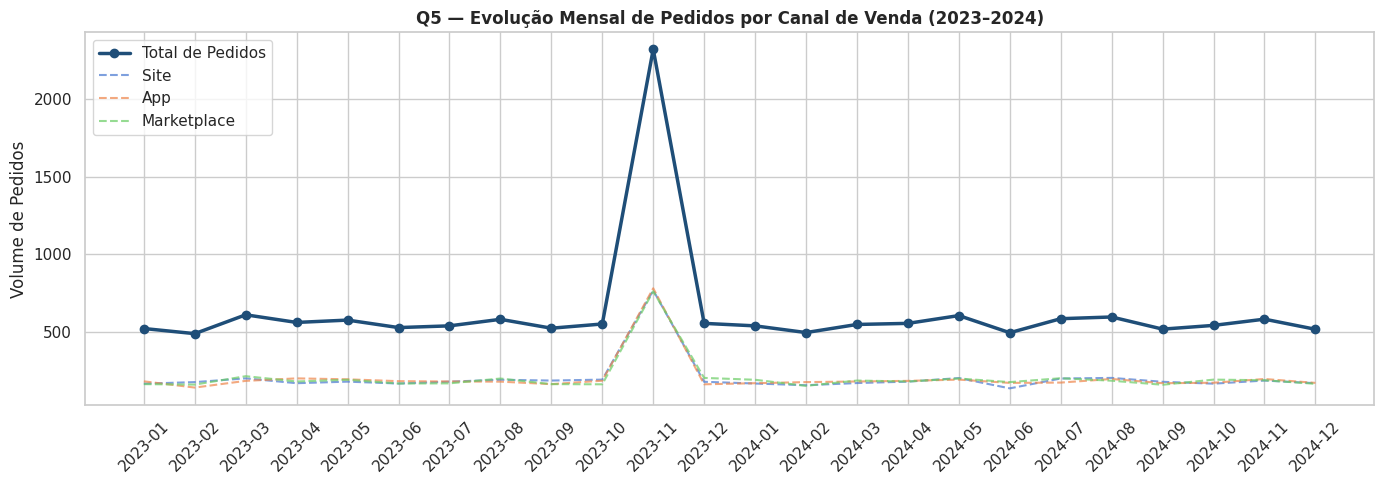

In [15]:
# === Q3: CATEGORIAS EM RECEITA VS. VOLUME (CORRIGIDO) ===
itens_status = itens_full.merge(
    pedidos[["id", "status"]], left_on="pedido_id", right_on="id", suffixes=("", "_ped")
)
q3_tab = itens_status.groupby("categoria", as_index=False).agg(
    unidades_vendidas=("quantidade", "sum"),
    linhas_item=("id", "count"),
    receita_liquida=("subtotal_liquido", "sum"),
    receita_nao_cancelada=("subtotal_liquido", lambda s: s[itens_status.loc[s.index, "status"] != "cancelado"].sum()),
    preco_medio_praticado=("preco_praticado", "mean")
)
q3_tab["rank_receita"] = q3_tab["receita_liquida"].rank(ascending=False).astype(int)
q3_tab["rank_volume"] = q3_tab["unidades_vendidas"].rank(ascending=False).astype(int)
q3_tab = q3_tab.sort_values("receita_liquida", ascending=False)
display(q3_tab)

# === Q4: CANAL DE AQUISIÇÃO — CANCELAMENTO E TICKET MÉDIO ===
print("\n=== Q4: CANAL DE AQUISIÇÃO — CANCELAMENTO E TICKET MÉDIO ===")
q4_tab = df_pedidos.groupby("canal_aquisicao", as_index=False).agg(
    clientes_unicos=("cliente_id", "nunique"),
    pedidos=("id", "count"),
    cancelados=("is_cancelado", "sum"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    ticket_medio_itens=("soma_liquida_itens", "mean"),
    ticket_mediano_itens=("soma_liquida_itens", "median"),
    pct_b2b=("segmento", lambda s: (s == "B2B").mean() * 100)
).sort_values("taxa_cancel_pct", ascending=False)
display(q4_tab)

ct_q4 = pd.crosstab(df_pedidos["canal_aquisicao"], df_pedidos["is_cancelado"])
chi2, p_val, _, _ = stats.chi2_contingency(ct_q4)
print(f"Teste Qui-Quadrado (Canal Aquisição x Cancelamento): chi2 = {chi2:.4f}, p-valor = {p_val:.4e}")

print("\nQuebra de Q4 por Segmento (B2C vs. B2B):")
display(df_pedidos.groupby(["canal_aquisicao", "segmento"]).agg(
    pedidos=("id", "count"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    ticket_medio_itens=("soma_liquida_itens", "mean")
))

# === Q5: EVOLUÇÃO MENSAL DE PEDIDOS E PICOS (2023–2024) ===
print("\n=== Q5: EVOLUÇÃO MENSAL DE PEDIDOS E PICOS (2023–2024) ===")
q5_mensal = df_pedidos.groupby("ano_mes", as_index=False).agg(
    total_pedidos=("id", "count"),
    cancelados=("is_cancelado", "sum"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    pct_com_cupom=("cupom_desconto", lambda s: (s == "sim").mean() * 100),
    receita_liquida=("soma_liquida_itens", "sum"),
    ped_site=("canal_venda", lambda s: (s == "site").sum()),
    ped_app=("canal_venda", lambda s: (s == "app").sum()),
    ped_mkt=("canal_venda", lambda s: (s == "marketplace").sum()),
)
display(q5_mensal)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(q5_mensal["ano_mes"], q5_mensal["total_pedidos"], marker="o", linewidth=2.5, color="#1f4e78", label="Total de Pedidos")
ax1.plot(q5_mensal["ano_mes"], q5_mensal["ped_site"], linestyle="--", alpha=0.7, label="Site")
ax1.plot(q5_mensal["ano_mes"], q5_mensal["ped_app"], linestyle="--", alpha=0.7, label="App")
ax1.plot(q5_mensal["ano_mes"], q5_mensal["ped_mkt"], linestyle="--", alpha=0.7, label="Marketplace")
ax1.set_title("Q5 — Evolução Mensal de Pedidos por Canal de Venda (2023–2024)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Volume de Pedidos")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc="upper left")
plt.tight_layout()
plt.show()

=== Q4: CANAL DE AQUISIÇÃO — CANCELAMENTO E TICKET MÉDIO ===


,canal_aquisicao,clientes_unicos,pedidos,cancelados,taxa_cancel_pct,ticket_medio_itens,ticket_mediano_itens,pct_b2b
2,paid_search,761,3965,1219,30.74,"11,137.20","9,182.36",20.23
0,indicação,735,3658,453,12.38,"10,932.04","8,941.48",19.93
1,orgânico,724,3616,426,11.78,"11,157.80","9,332.90",19.19
3,redes_sociais,757,3761,439,11.67,"11,003.20","9,144.52",20.98


Teste Qui-Quadrado (Canal Aquisição x Cancelamento): chi2 = 734.4185, p-valor = 7.2203e-159

Quebra de Q4 por Segmento (B2C vs. B2B):


pedidos  taxa_cancel_pct  ticket_medio_itens
canal_aquisicao segmento                                              
indicação       B2B           729            11.66           10,691.32
                B2C          2929            12.56           10,991.95
orgânico        B2B           694            11.82           11,070.44
                B2C          2922            11.77           11,178.55
paid_search     B2B           802            32.42           11,295.86
                B2C          3163            30.32           11,096.97
redes_sociais   B2B           789            12.17           10,913.88
                B2C          2972            11.54           11,026.92


=== Q5: EVOLUÇÃO MENSAL DE PEDIDOS E PICOS (2023–2024) ===


,ano_mes,total_pedidos,cancelados,taxa_cancel_pct,pct_com_cupom,receita_liquida,ped_site,ped_app,ped_mkt
0,2023-01,525,78,14.86,36.95,"5,413,463.94",171,186,168
1,2023-02,492,62,12.60,36.59,"5,479,889.64",181,146,165
2,2023-03,613,103,16.80,36.54,"6,823,472.11",205,189,219
3,2023-04,564,95,16.84,36.52,"6,270,107.84",174,205,185
4,2023-05,579,96,16.58,35.58,"6,342,077.75",184,199,196
5,2023-06,531,93,17.51,33.90,"6,131,097.84",172,187,172
6,2023-07,542,94,17.34,34.87,"5,966,847.53",184,185,173
7,2023-08,584,108,18.49,33.90,"6,089,829.55",196,184,204
8,2023-09,527,95,18.03,34.72,"5,955,955.48",191,168,168
9,2023-10,554,95,17.15,33.39,"6,306,256.40",197,190,167


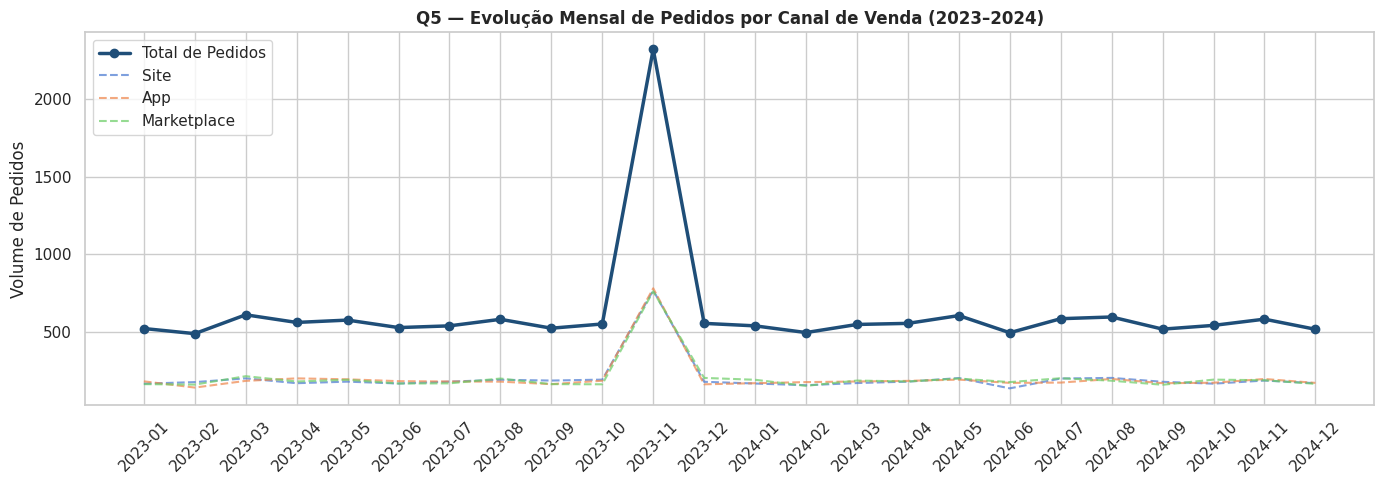

In [16]:
# Q4: Canal de Aquisição vs. Cancelamento e Ticket Médio
print("=== Q4: CANAL DE AQUISIÇÃO — CANCELAMENTO E TICKET MÉDIO ===")
q4_tab = df_pedidos.groupby("canal_aquisicao", as_index=False).agg(
    clientes_unicos=("cliente_id", "nunique"),
    pedidos=("id", "count"),
    cancelados=("is_cancelado", "sum"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    ticket_medio_itens=("soma_liquida_itens", "mean"),
    ticket_mediano_itens=("soma_liquida_itens", "median"),
    pct_b2b=("segmento", lambda s: (s == "B2B").mean() * 100)
).sort_values("taxa_cancel_pct", ascending=False)
display(q4_tab)

# Teste Qui-Quadrado para independência entre canal_aquisicao e cancelamento
ct_q4 = pd.crosstab(df_pedidos["canal_aquisicao"], df_pedidos["is_cancelado"])
chi2, p_val, _, _ = stats.chi2_contingency(ct_q4)
print(f"Teste Qui-Quadrado (Canal Aquisição x Cancelamento): chi2 = {chi2:.4f}, p-valor = {p_val:.4e}")

print("\nQuebra de Q4 por Segmento (B2C vs. B2B):")
display(df_pedidos.groupby(["canal_aquisicao", "segmento"]).agg(
    pedidos=("id", "count"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    ticket_medio_itens=("soma_liquida_itens", "mean")
))

# Q5: Evolução Mensal e Picos (2023-2024)
print("\n=== Q5: EVOLUÇÃO MENSAL DE PEDIDOS E PICOS (2023–2024) ===")
q5_mensal = df_pedidos.groupby("ano_mes", as_index=False).agg(
    total_pedidos=("id", "count"),
    cancelados=("is_cancelado", "sum"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    pct_com_cupom=("cupom_desconto", lambda s: (s == "sim").mean() * 100),
    receita_liquida=("soma_liquida_itens", "sum"),
    ped_site=("canal_venda", lambda s: (s == "site").sum()),
    ped_app=("canal_venda", lambda s: (s == "app").sum()),
    ped_mkt=("canal_venda", lambda s: (s == "marketplace").sum()),
)
display(q5_mensal)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(q5_mensal["ano_mes"], q5_mensal["total_pedidos"], marker="o", linewidth=2.5, color="#1f4e78", label="Total de Pedidos")
ax1.plot(q5_mensal["ano_mes"], q5_mensal["ped_site"], linestyle="--", alpha=0.7, label="Site")
ax1.plot(q5_mensal["ano_mes"], q5_mensal["ped_app"], linestyle="--", alpha=0.7, label="App")
ax1.plot(q5_mensal["ano_mes"], q5_mensal["ped_mkt"], linestyle="--", alpha=0.7, label="Marketplace")
ax1.set_title("Q5 — Evolução Mensal de Pedidos por Canal de Venda (2023–2024)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Volume de Pedidos")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [17]:
print("=== Q7: DESEMPENHO POR FORNECEDOR (VENDAS, CANCELAMENTOS, AVALIAÇÕES E TICKETS) ===")

aval_prod = avaliacoes.merge(
    produtos[["id", "nome", "categoria", "fornecedor"]], left_on="produto_id", right_on="id", suffixes=("", "_prod")
)
agg_aval_forn = aval_prod.groupby("fornecedor", as_index=False).agg(
    qtd_avaliacoes=("id", "count"),
    nota_media=("nota", "mean"),
    pct_notas_baixas_1_2=("nota", lambda s: (s <= 2).mean() * 100)
)

itens_ped_forn = itens_full.merge(
    pedidos[["id", "status", "data_pedido"]], left_on="pedido_id", right_on="id", suffixes=("", "_ped")
)
agg_vendas_forn = itens_ped_forn.groupby("fornecedor", as_index=False).agg(
    itens_vendidos=("id", "count"),
    unidades=("quantidade", "sum"),
    receita_liquida=("subtotal_liquido", "sum"),
    taxa_itens_cancelados_pct=("status", lambda s: (s == "cancelado").mean() * 100)
)

ped_forn_unicos = itens_full[["pedido_id", "fornecedor"]].drop_duplicates()
tickets_forn = tickets.merge(ped_forn_unicos, on="pedido_id", how="inner")
agg_tickets_forn = tickets_forn.groupby("fornecedor", as_index=False).agg(
    tickets_associados=("id", "count"),
    tickets_defeito_troca=("categoria_problema", lambda s: s.isin(["defeito", "troca"]).sum())
)

q7_forn = agg_vendas_forn.merge(agg_aval_forn, on="fornecedor", how="left").merge(agg_tickets_forn, on="fornecedor", how="left")
q7_forn["tickets_por_100_itens"] = q7_forn["tickets_associados"] / q7_forn["itens_vendidos"] * 100
q7_forn = q7_forn.sort_values("nota_media", ascending=True)
display(q7_forn)

print("\n=== INVESTIGAÇÃO DO PICO DE CHAMADOS DE SUPORTE (2023–2024) ===")
tickets["ano_mes"] = tickets["data_abertura"].dt.to_period("M").astype(str)
tickets_mensal = tickets.pivot_table(index="ano_mes", columns="categoria_problema", values="id", aggfunc="count", fill_value=0)
tickets_mensal["TOTAL"] = tickets_mensal.sum(axis=1)
display(tickets_mensal)

tickets_forn["ano_mes"] = tickets_forn["data_abertura"].dt.to_period("M").astype(str)
print("\nTickets mensais associados a cada fornecedor (últimos 16 meses):")
display(tickets_forn.pivot_table(index="ano_mes", columns="fornecedor", values="id", aggfunc="count", fill_value=0).tail(16))

print("\nPrincipais comentários negativos (nota <= 2) por fornecedor:")
for forn, grp in aval_prod[aval_prod["nota"] <= 2].groupby("fornecedor"):
    top_com = grp["comentario"].dropna().value_counts().head(3).to_dict()
    print(f" - {forn} (n={len(grp)}): {top_com}")

=== Q7: DESEMPENHO POR FORNECEDOR (VENDAS, CANCELAMENTOS, AVALIAÇÕES E TICKETS) ===


,fornecedor,itens_vendidos,unidades,receita_liquida,taxa_itens_cancelados_pct,qtd_avaliacoes,nota_media,pct_notas_baixas_1_2,tickets_associados,tickets_defeito_troca,tickets_por_100_itens
1,DeltaFornece ME,4390,13023,"18,421,134.82",16.95,985,2.30,59.90,1007,374,22.94
7,SulFornece SA,4098,12241,"16,340,237.77",18.18,845,3.62,22.37,956,321,23.33
6,NorteImport Ltda,3893,11742,"16,261,722.79",17.57,824,3.66,22.09,928,329,23.84
8,TechBrasil Ltda,4890,14625,"24,861,973.14",17.24,1027,3.74,20.25,1191,434,24.36
0,AlphaSupply,3098,9410,"12,588,798.88",17.46,684,3.80,18.13,770,269,24.85
3,GlobalBR Comércio,3994,12018,"18,246,046.84",17.33,912,3.80,17.43,964,329,24.14
2,FornecedorX,3568,10715,"20,006,833.78",17.04,789,3.81,18.76,883,321,24.75
5,MegaDistribuidora,5493,16403,"25,768,891.85",16.46,1241,3.82,17.73,1217,435,22.16
4,MarcoPolo Distribuição,3316,9987,"13,382,426.80",16.19,693,3.84,17.75,807,283,24.34



=== INVESTIGAÇÃO DO PICO DE CHAMADOS DE SUPORTE (2023–2024) ===


categoria_problema,atraso,cobrança,defeito,dúvida,troca,TOTAL
ano_mes,,,,,,
2023-01,21,10,13,16,13,73
2023-02,28,25,19,23,23,118
2023-03,38,19,41,38,23,159
2023-04,26,28,19,33,27,133
2023-05,35,30,41,31,31,168
2023-06,34,26,33,36,28,157
2023-07,33,23,15,41,26,138
2023-08,42,32,23,33,30,160
2023-09,44,23,24,36,24,151



Tickets mensais associados a cada fornecedor (últimos 16 meses):


fornecedor,AlphaSupply,DeltaFornece ME,FornecedorX,GlobalBR Comércio,MarcoPolo Distribuição,MegaDistribuidora,NorteImport Ltda,SulFornece SA,TechBrasil Ltda
ano_mes,,,,,,,,,
2023-09,28,39,23,36,27,51,44,35,38
2023-10,35,31,42,36,29,55,36,36,50
2023-11,64,109,89,107,76,120,80,89,113
2023-12,82,96,78,101,71,126,93,100,109
2024-01,20,45,27,29,27,34,37,22,35
2024-02,26,37,29,28,29,39,27,39,34
2024-03,23,30,27,28,18,39,24,24,28
2024-04,29,36,30,30,23,41,30,30,56
2024-05,39,40,42,38,34,59,44,35,58



Principais comentários negativos (nota <= 2) por fornecedor:
 - AlphaSupply (n=124): {'Demorou muito para chegar.': 27, 'Qualidade abaixo do esperado.': 23, 'Não recomendo, péssima experiência.': 22}
 - DeltaFornece ME (n=590): {'Qualidade abaixo do esperado.': 107, 'Não recomendo, péssima experiência.': 107, 'Veio diferente do anunciado.': 92}
 - FornecedorX (n=148): {'Veio diferente do anunciado.': 31, 'Produto veio com defeito.': 28, 'Qualidade abaixo do esperado.': 27}
 - GlobalBR Comércio (n=159): {'Demorou muito para chegar.': 34, 'Não recomendo, péssima experiência.': 32, 'Veio diferente do anunciado.': 27}
 - MarcoPolo Distribuição (n=123): {'Não recomendo, péssima experiência.': 25, 'Veio diferente do anunciado.': 23, 'Demorou muito para chegar.': 20}
 - MegaDistribuidora (n=220): {'Demorou muito para chegar.': 46, 'Veio diferente do anunciado.': 37, 'Qualidade abaixo do esperado.': 34}
 - NorteImport Ltda (n=182): {'Qualidade abaixo do esperado.': 33, 'Produto veio com defei

In [18]:
# === RAIO-X Q6: TICKET MÉDIO POR SEGMENTO E CORRELAÇÃO ===
rec_seg = rec.merge(clientes[["id", "segmento"]], left_on="cliente_id", right_on="id", suffixes=("", "_cli"))
print("\n=== RAIO-X Q6: TICKET MÉDIO POR SEGMENTO (PEDIDOS vs. ITENS) ===")
display(rec_seg.groupby("segmento").agg(
    qtd_pedidos=("id", "count"),
    nulos_valor_total=("valor_total", lambda s: s.isna().sum()),
    media_valor_total_pedidos=("valor_total", "mean"),
    mediana_valor_total_pedidos=("valor_total", "median"),
    media_soma_liquida_itens=("soma_liquida_itens", "mean"),
    mediana_soma_liquida_itens=("soma_liquida_itens", "median"),
    correlacao=("valor_total", lambda s: s.corr(rec_seg.loc[s.index, "soma_liquida_itens"]))
))

print("\n=== CHECAGEM DE PREÇO UNITÁRIO vs. PREÇO PRATICADO ===")
itens_full["ratio_preco"] = itens_full["preco_praticado"] / itens_full["preco_unitario"]
print(itens_full["ratio_preco"].describe())


=== RAIO-X Q6: TICKET MÉDIO POR SEGMENTO (PEDIDOS vs. ITENS) ===


,qtd_pedidos,nulos_valor_total,media_valor_total_pedidos,mediana_valor_total_pedidos,media_soma_liquida_itens,mediana_soma_liquida_itens,correlacao
segmento,,,,,,,
B2B,3014,13,"7,778.34","7,803.97","10,997.74","9,159.82",-0.02
B2C,11986,66,"1,264.72","1,255.37","11,073.83","9,159.21",-0.01



=== CHECAGEM DE PREÇO UNITÁRIO vs. PREÇO PRATICADO ===
count   36,740.00
mean         0.93
std          0.08
min          0.70
25%          0.91
50%          0.96
75%          0.98
max          1.00
Name: ratio_preco, dtype: float64


In [19]:
# Mini-checagem complementar: Q2, Camila vs Rogério e anatomia de 2023-11
print("=== CAMILA vs. ROGÉRIO (RESUMO ANUAL) ===")
display(comp_ano)

print("\n=== Q2: DISTRIBUIÇÃO POR STATUS ===")
display(q2_tab)

print("\n=== ANATOMIA DO PICO 2023-11 vs. DEMAIS MESES ===")
df_pedidos["is_nov23"] = (df_pedidos["ano_mes"] == "2023-11")
display(df_pedidos.groupby("is_nov23").agg(
    pedidos=("id", "count"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    pct_paid_search=("canal_aquisicao", lambda s: (s == "paid_search").mean() * 100),
    pct_b2b=("segmento", lambda s: (s == "B2B").mean() * 100),
    ticket_pedidos_valido=("valor_total", "mean"),
    ticket_itens=("soma_liquida_itens", "mean")
))

=== CAMILA vs. ROGÉRIO (RESUMO ANUAL) ===


,total_pedidos,pedidos_cancelados,pedidos_entregues,pedidos_em_aberto,gmv_total_itens,gmv_cancelado_itens,taxa_cancel_total_%,taxa_cancel_finalizados_%,taxa_cancel_gmv_%
ano,,,,,,,,,
2023,8386,1407,5558,1421,"92,351,884.94","15,453,693.49",16.78,20.20,16.73
2024,6614,1130,4401,1083,"73,526,181.73","12,500,888.71",17.08,20.43,17.00



=== Q2: DISTRIBUIÇÃO POR STATUS ===


,status,qtd_pedidos,receita_itens,ticket_medio_itens,pct_pedidos,pct_receita
3,entregue,9959,"110,840,777.33","11,129.71",66.39,66.82
0,cancelado,2537,"27,954,582.20","11,018.76",16.91,16.85
2,em_transito,1371,"14,944,694.41","10,900.58",9.14,9.01
1,devolvido,1133,"12,138,012.73","10,713.16",7.55,7.32



=== ANATOMIA DO PICO 2023-11 vs. DEMAIS MESES ===


,pedidos,taxa_cancel_pct,pct_paid_search,pct_b2b,ticket_pedidos_valido,ticket_itens
is_nov23,,,,,,
False,12683,16.83,26.49,20.15,"2,583.33","11,054.63"
True,2317,17.39,26.11,19.77,"2,528.04","11,079.93"


In [20]:
# 1. Q2 e Q4 recalculados com Pedidos.valor_total (fonte confiável da Q6)
print("=== Q2 OFICIAL (COM Pedidos.valor_total) ===")
q2_oficial = df_pedidos.groupby("status", as_index=False).agg(
    qtd_pedidos=("id", "count"),
    receita_pedidos=("valor_total", "sum"),
    ticket_medio_pedidos=("valor_total", "mean")
).sort_values("qtd_pedidos", ascending=False)
q2_oficial["pct_pedidos"] = q2_oficial["qtd_pedidos"] / q2_oficial["qtd_pedidos"].sum() * 100
q2_oficial["pct_receita"] = q2_oficial["receita_pedidos"] / q2_oficial["receita_pedidos"].sum() * 100
display(q2_oficial)

print("\n=== DISTRIBUIÇÃO DE 'em_transito' POR ANO/MÊS ===")
print(df_pedidos[df_pedidos["status"] == "em_transito"]["ano_mes"].value_counts().sort_index().tail(10))
print("Total em_transito em 2023:", (df_pedidos[df_pedidos["status"] == "em_transito"]["ano"] == 2023).sum())

print("\n=== Q4 OFICIAL (TICKET MÉDIO COM Pedidos.valor_total) ===")
display(df_pedidos.groupby("canal_aquisicao", as_index=False).agg(
    pedidos=("id", "count"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100),
    ticket_medio_pedidos=("valor_total", "mean")
))

# 2. Rastreando as visões da Camila (+40%) e do Rogério (18% -> 16%)
print("\n=== RASTREAMENTO CAMILA (+40%) vs. ROGÉRIO (18% -> 16%) ===")
df_pedidos["semestre"] = df_pedidos["data_pedido"].dt.year.astype(str) + "-S" + np.where(df_pedidos["data_pedido"].dt.month <= 6, "1", "2")
display(df_pedidos.groupby("semestre").agg(
    pedidos=("id", "count"),
    cancelados=("is_cancelado", "sum"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100)
))
display(df_pedidos.groupby(["ano", "canal_aquisicao"]).agg(
    pedidos=("id", "count"),
    cancelados=("is_cancelado", "sum"),
    taxa_cancel_pct=("is_cancelado", lambda s: s.mean() * 100)
))

=== Q2 OFICIAL (COM Pedidos.valor_total) ===


,status,qtd_pedidos,receita_pedidos,ticket_medio_pedidos,pct_pedidos,pct_receita
3,entregue,9959,"25,436,542.40","2,569.09",66.39,66.21
0,cancelado,2537,"6,645,370.22","2,630.79",16.91,17.30
2,em_transito,1371,"3,514,450.94","2,574.69",9.14,9.15
1,devolvido,1133,"2,821,889.09","2,499.46",7.55,7.35



=== DISTRIBUIÇÃO DE 'em_transito' POR ANO/MÊS ===
ano_mes
2024-03    48
2024-04    48
2024-05    57
2024-06    41
2024-07    47
2024-08    54
2024-09    38
2024-10    52
2024-11    59
2024-12    34
Name: count, dtype: int64
Total em_transito em 2023: 788

=== Q4 OFICIAL (TICKET MÉDIO COM Pedidos.valor_total) ===


,canal_aquisicao,pedidos,taxa_cancel_pct,ticket_medio_pedidos
0,indicação,3658,12.38,"2,565.98"
1,orgânico,3616,11.78,"2,521.15"
2,paid_search,3965,30.74,"2,553.51"
3,redes_sociais,3761,11.67,"2,657.17"



=== RASTREAMENTO CAMILA (+40%) vs. ROGÉRIO (18% -> 16%) ===


,pedidos,cancelados,taxa_cancel_pct
semestre,,,
2023-S1,3304,527,15.95
2023-S2,5082,880,17.32
2024-S1,3256,575,17.66
2024-S2,3358,555,16.53


pedidos  cancelados  taxa_cancel_pct
ano  canal_aquisicao                                      
2023 indicação           2039         269            13.19
     orgânico            2020         243            12.03
     paid_search         2196         654            29.78
     redes_sociais       2131         241            11.31
2024 indicação           1619         184            11.37
     orgânico            1596         183            11.47
     paid_search         1769         565            31.94
     redes_sociais       1630         198            12.15

In [21]:
# Prova final contra a hipótese de "captura apenas do 1º item"
ped_1_item = validos[validos["qtd_itens"] == 1]
bate_1_item = np.isclose(ped_1_item["diff_liquida"], 0, atol=0.05).sum()
print(f"Pedidos com apenas 1 item: {len(ped_1_item):,} | Reconciliam: {bate_1_item} ({bate_1_item/len(ped_1_item)*100:.2f}%)")

Pedidos com apenas 1 item: 4,408 | Reconciliam: 0 (0.00%)
